In [1]:
#import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
#load the datasheet
df = pd.read_csv("bank.csv", sep=";")

print("Dataset loaded successfully!")

print("Shape:", df.shape)

#display the first 5 record

df.head()



Dataset loaded successfully!
Shape: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [6]:
#Check dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


In [7]:
#check the target distribution
print(df['y'].value_counts())

print("\nPercentage distribution:")

print(df['y'].value_counts(normalize=True) * 100)

y
no     4000
yes     521
Name: count, dtype: int64

Percentage distribution:
y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64


In [8]:
#Exploratory Data Analysis (EDA)
#checking missing values
# Count missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Total missing values: 0


In [9]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [10]:
# Count customers in each target category
print("Target variable distribution:")
print(df["y"].value_counts())

# Calculate percentage distribution
print("\nTarget percentage:")
print(df["y"].value_counts(normalize=True) * 100)

Target variable distribution:
y
no     4000
yes     521
Name: count, dtype: int64

Target percentage:
y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64


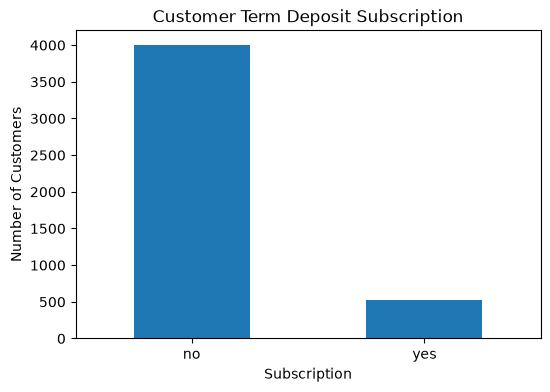

In [11]:
#visualize the target distribution
import matplotlib.pyplot as plt

df["y"].value_counts().plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.title("Customer Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

In [12]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

# Display descriptive statistics
print(df[numerical_columns].describe())

               age       balance          day     duration     campaign  \
count  4521.000000   4521.000000  4521.000000  4521.000000  4521.000000   
mean     41.170095   1422.657819    15.915284   263.961292     2.793630   
std      10.576211   3009.638142     8.247667   259.856633     3.109807   
min      19.000000  -3313.000000     1.000000     4.000000     1.000000   
25%      33.000000     69.000000     9.000000   104.000000     1.000000   
50%      39.000000    444.000000    16.000000   185.000000     2.000000   
75%      49.000000   1480.000000    21.000000   329.000000     3.000000   
max      87.000000  71188.000000    31.000000  3025.000000    50.000000   

             pdays     previous  
count  4521.000000  4521.000000  
mean     39.766645     0.542579  
std     100.121124     1.693562  
min      -1.000000     0.000000  
25%      -1.000000     0.000000  
50%      -1.000000     0.000000  
75%      -1.000000     0.000000  
max     871.000000    25.000000  


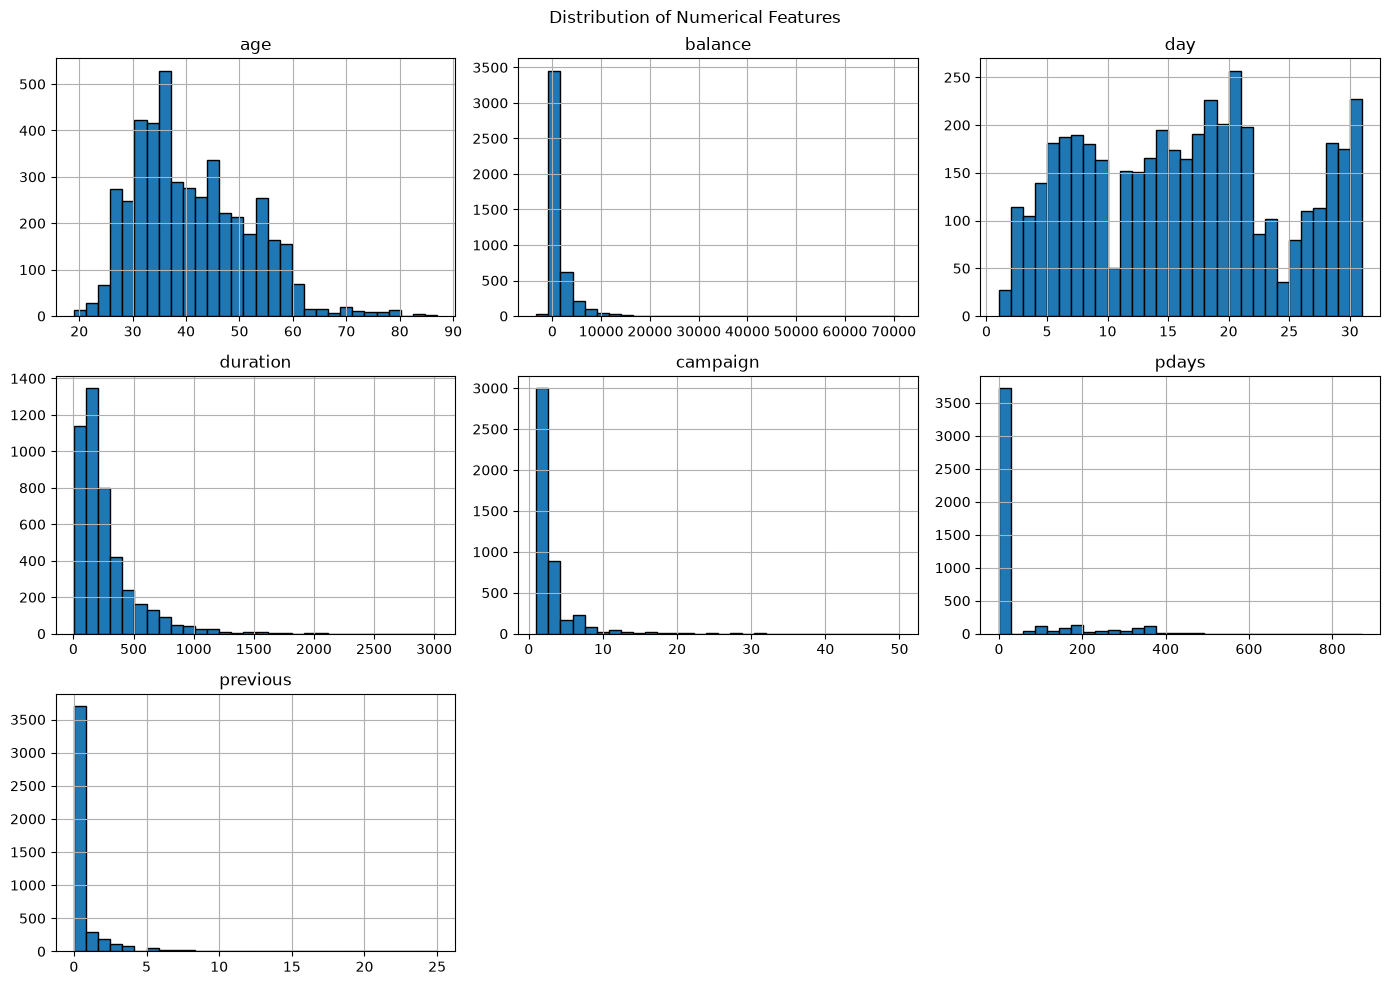

In [13]:
#Visualize numerical feature distributions

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [14]:
#Explore categorical features
categorical_columns = df.select_dtypes(include=["object", "str"]).columns

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts())


Column: job
job
management       969
blue-collar      946
technician       768
admin.           478
services         417
retired          230
self-employed    183
entrepreneur     168
unemployed       128
housemaid        112
student           84
unknown           38
Name: count, dtype: int64

Column: marital
marital
married     2797
single      1196
divorced     528
Name: count, dtype: int64

Column: education
education
secondary    2306
tertiary     1350
primary       678
unknown       187
Name: count, dtype: int64

Column: default
default
no     4445
yes      76
Name: count, dtype: int64

Column: housing
housing
yes    2559
no     1962
Name: count, dtype: int64

Column: loan
loan
no     3830
yes     691
Name: count, dtype: int64

Column: contact
contact
cellular     2896
unknown      1324
telephone     301
Name: count, dtype: int64

Column: month
month
may    1398
jul     706
aug     633
jun     531
nov     389
apr     293
feb     222
jan     148
oct      80
sep      52
mar      49

y                 no    yes
job                        
admin.         87.87  12.13
blue-collar    92.71   7.29
entrepreneur   91.07   8.93
housemaid      87.50  12.50
management     86.48  13.52
retired        76.52  23.48
self-employed  89.07  10.93
services       90.89   9.11
student        77.38  22.62
technician     89.19  10.81
unemployed     89.84  10.16
unknown        81.58  18.42


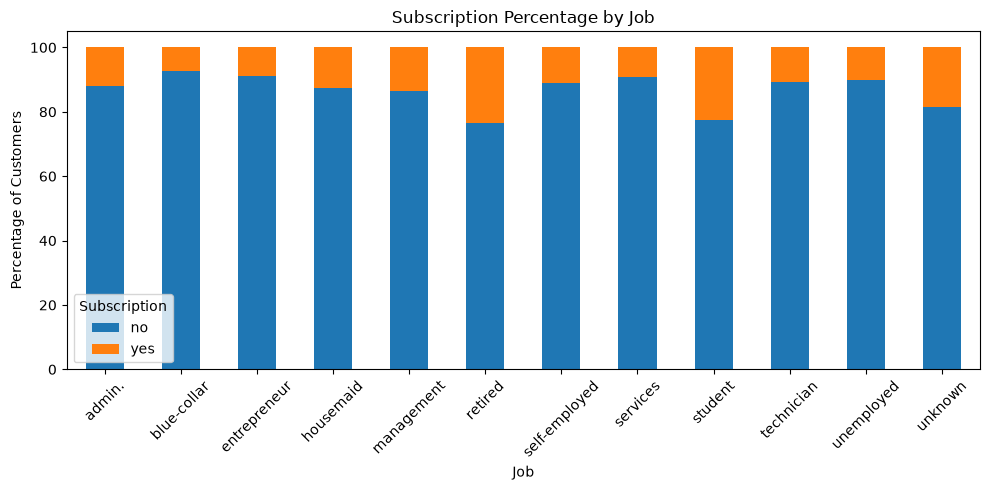

In [15]:
#Subscription percentage by job

import pandas as pd
import matplotlib.pyplot as plt

job_subscription = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

print(job_subscription.round(2))

job_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Subscription Percentage by Job")
plt.xlabel("Job")
plt.ylabel("Percentage of Customers")
plt.legend(title="Subscription")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

y             no    yes
education              
primary    90.56   9.44
secondary  89.38  10.62
tertiary   85.70  14.30
unknown    89.84  10.16


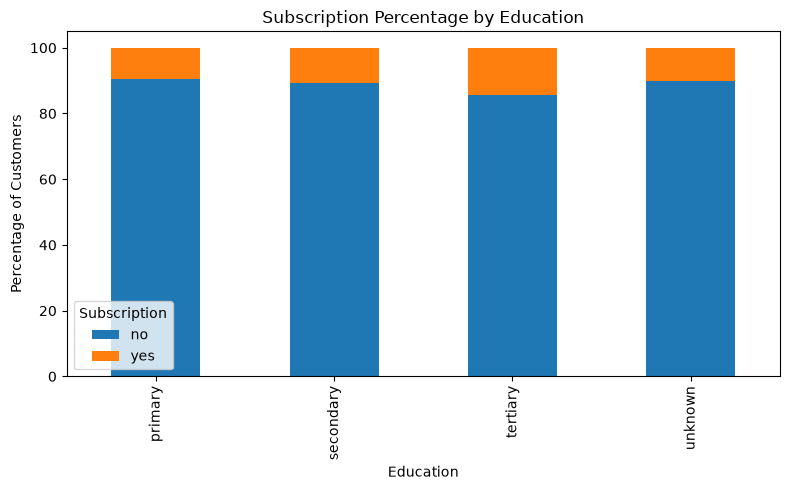

In [16]:
#Subscription percentage by education

education_subscription = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

print(education_subscription.round(2))

education_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Subscription Percentage by Education")
plt.xlabel("Education")
plt.ylabel("Percentage of Customers")
plt.legend(title="Subscription")
plt.tight_layout()
plt.show()

y            no    yes
poutcome              
failure   87.14  12.86
other     80.71  19.29
success   35.66  64.34
unknown   90.90   9.10


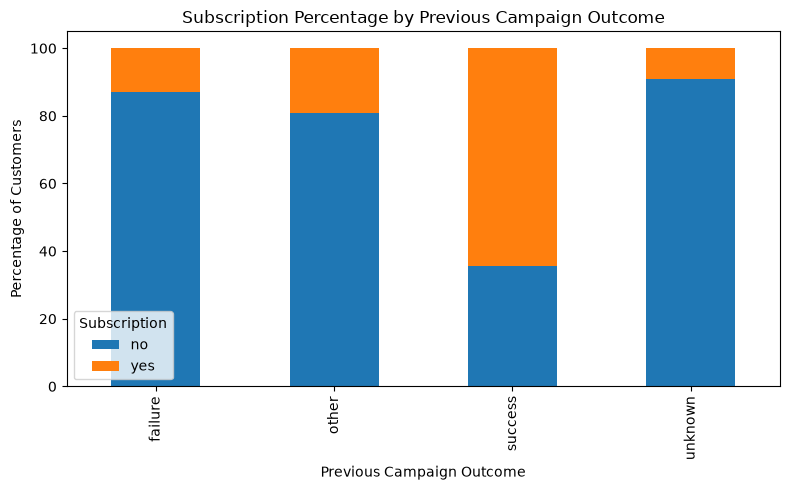

In [17]:
# Subscription percentage by previous campaign outcome

poutcome_subscription = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

print(poutcome_subscription.round(2))

poutcome_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Subscription Percentage by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Percentage of Customers")
plt.legend(title="Subscription")
plt.tight_layout()
plt.show()

In [18]:
# data preprocessing

# Remove duration because it is known only after customer contact
X = df.drop(columns=["y", "duration"])

# Target variable
y = df["y"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

Input features shape: (4521, 15)
Target shape: (4521,)

Input columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


In [19]:
#Separate numerical and categorical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [20]:
#splitting training and test data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (3616, 15)
Testing features: (905, 15)

Training target distribution:
y
no     88.46792
yes    11.53208
Name: proportion, dtype: float64

Testing target distribution:
y
no     88.508287
yes    11.491713
Name: proportion, dtype: float64


In [21]:
#Import preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

In [23]:
#Create the numerical and categorical transformers

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

print("Preprocessing transformers created successfully!")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("ColumnTransformer created successfully!")

Preprocessing transformers created successfully!
ColumnTransformer created successfully!


In [24]:
#encode the target variable

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Target classes:", label_encoder.classes_)
print("Encoded training target:", y_train_encoded[:10])
print("Encoded testing target:", y_test_encoded[:10])

Target classes: ['no' 'yes']
Encoded training target: [0 0 0 0 0 0 0 0 0 0]
Encoded testing target: [1 0 0 0 0 0 0 1 1 0]


In [25]:
# test the preprocessing

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (3616, 15)
Processed training shape: (3616, 50)

Original testing shape: (905, 15)
Processed testing shape: (905, 50)


In [26]:
#import the libraries

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

In [28]:
#Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numerical_features),
                ("cat", OneHotEncoder(handle_unknown="ignore"),
                 categorical_features)
            ]
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

In [29]:
# Train Logistic Regression
logistic_model.fit(X_train, y_train_encoded)

print("Logistic Regression training completed!")


Logistic Regression training completed!


In [30]:
#make prediction

y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test_encoded[:10])

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10])

First 10 actual values:
[1 0 0 0 0 0 0 1 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 1 1 0]


In [31]:
#Evaluate Logistic Regression

lr_accuracy = accuracy_score(y_test_encoded, y_pred_lr)

lr_precision = precision_score(
    y_test_encoded, y_pred_lr, zero_division=0
)

lr_recall = recall_score(
    y_test_encoded, y_pred_lr, zero_division=0
)

lr_f1 = f1_score(
    y_test_encoded, y_pred_lr, zero_division=0
)

lr_auc = roc_auc_score(y_test_encoded, y_prob_lr)

lr_mcc = matthews_corrcoef(y_test_encoded, y_pred_lr)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("AUC      :", round(lr_auc, 4))
print("MCC      :", round(lr_mcc, 4))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy : 0.705
Precision: 0.2237
Recall   : 0.6346
F1 Score : 0.3308
AUC      : 0.735
MCC      : 0.2373


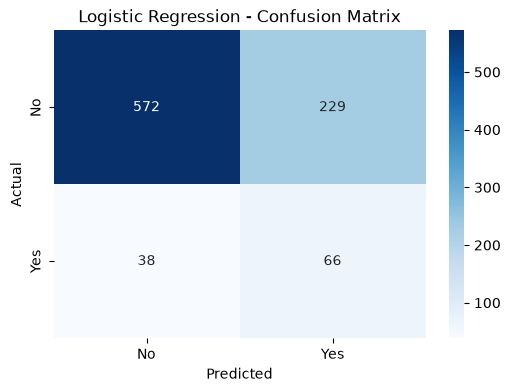

In [32]:
#Confusion matrix

import seaborn as sns

cm = confusion_matrix(y_test_encoded, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [33]:
# Classification report

print(
    classification_report(
        y_test_encoded,
        y_pred_lr,
        target_names=["No", "Yes"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

          No       0.94      0.71      0.81       801
         Yes       0.22      0.63      0.33       104

    accuracy                           0.70       905
   macro avg       0.58      0.67      0.57       905
weighted avg       0.86      0.70      0.76       905



# Decision Tree
A Decision Tree works differently from Logistic Regression.

Instead of calculating probabilities using a linear equation and sigmoid function, it learns a sequence of decision rules.

In [36]:
# Import Decision Tree lib

from sklearn.tree import DecisionTreeClassifier



In [37]:
#Create the Decision Tree pipeline

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numerical_features),
                ("cat", OneHotEncoder(handle_unknown="ignore"),
                 categorical_features)
            ]
        )),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42,
            max_depth=5
        ))
    ]
)

In [38]:
#Train Decision Tree
decision_tree_model.fit(X_train, y_train_encoded)

print("Decision Tree training completed!")

Decision Tree training completed!


In [40]:
#Make predictions
y_pred_dt = decision_tree_model.predict(X_test)

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test_encoded[:10])

print("\nFirst 10 predicted values:")
print(y_pred_dt[:10])

First 10 actual values:
[1 0 0 0 0 0 0 1 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 0 0]


In [41]:
#Evaluate Decision Tree

dt_accuracy = accuracy_score(y_test_encoded, y_pred_dt)

dt_precision = precision_score(
    y_test_encoded, y_pred_dt, zero_division=0
)

dt_recall = recall_score(
    y_test_encoded, y_pred_dt, zero_division=0
)

dt_f1 = f1_score(
    y_test_encoded, y_pred_dt, zero_division=0
)

dt_auc = roc_auc_score(y_test_encoded, y_prob_dt)

dt_mcc = matthews_corrcoef(y_test_encoded, y_pred_dt)

print("DECISION TREE RESULTS")
print("---------------------")

print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("AUC      :", round(dt_auc, 4))
print("MCC      :", round(dt_mcc, 4))

DECISION TREE RESULTS
---------------------
Accuracy : 0.7724
Precision: 0.2287
Recall   : 0.4135
F1 Score : 0.2945
AUC      : 0.6788
MCC      : 0.1827


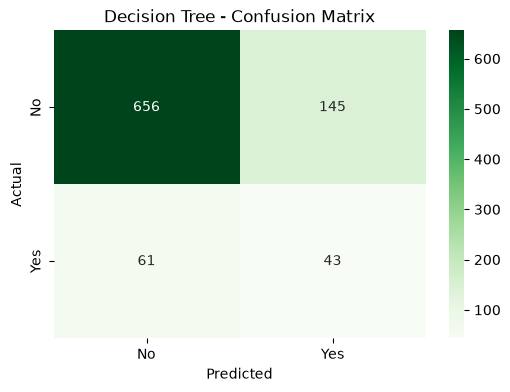

In [42]:
#Decision Tree confusion matrix
cm_dt = confusion_matrix(y_test_encoded, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# K-Nearest Neighbors (KNN)
KNN uses a different approach.

It predicts the class of a new customer by examining the classes of the nearest customers in the training dataset.

In [43]:
#Import KNN

from sklearn.neighbors import KNeighborsClassifier

In [44]:
#Create KNN pipeline

knn_model = Pipeline(
    steps=[
        ("preprocessor", ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numerical_features),
                ("cat", OneHotEncoder(handle_unknown="ignore"),
                 categorical_features)
            ]
        )),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            weights="uniform"
        ))
    ]
)

In [45]:
#Train KNN

knn_model.fit(X_train, y_train_encoded)

print("KNN training completed!")

KNN training completed!


In [46]:
#Make predictions
y_pred_knn = knn_model.predict(X_test)

y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test_encoded[:10])

print("\nFirst 10 predicted values:")
print(y_pred_knn[:10])

First 10 actual values:
[1 0 0 0 0 0 0 1 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 0 0]


In [47]:
#Evaluate KNN

knn_accuracy = accuracy_score(y_test_encoded, y_pred_knn)

knn_precision = precision_score(
    y_test_encoded, y_pred_knn, zero_division=0
)

knn_recall = recall_score(
    y_test_encoded, y_pred_knn, zero_division=0
)

knn_f1 = f1_score(
    y_test_encoded, y_pred_knn, zero_division=0
)

knn_auc = roc_auc_score(y_test_encoded, y_prob_knn)

knn_mcc = matthews_corrcoef(y_test_encoded, y_pred_knn)

print("KNN RESULTS")
print("-----------")

print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("AUC      :", round(knn_auc, 4))
print("MCC      :", round(knn_mcc, 4))

KNN RESULTS
-----------
Accuracy : 0.8762
Precision: 0.2778
Recall   : 0.0481
F1 Score : 0.082
AUC      : 0.6112
MCC      : 0.0727


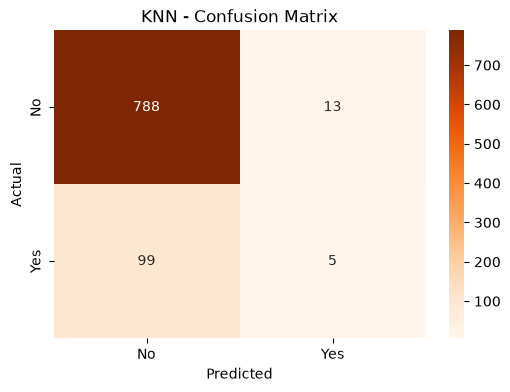

In [48]:
#KNN confusion matrix
cm_knn = confusion_matrix(y_test_encoded, y_pred_knn)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Naive Bayes
Naive Bayes is based on Bayes' theorem.

It calculates the probability of a class given the observed features.

Bayes' theorem

In [49]:
#Import Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB

In [50]:
#Create the Naive Bayes pipeline

nb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    sparse_threshold=0
)

naive_bayes_model = Pipeline(
    steps=[
        ("preprocessor", nb_preprocessor),
        ("classifier", GaussianNB())
    ]
)

print("Naive Bayes pipeline created successfully!")

Naive Bayes pipeline created successfully!


In [51]:
#Train Naive Bayes
naive_bayes_model.fit(X_train, y_train_encoded)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [52]:
#Make predictions

y_pred_nb = naive_bayes_model.predict(X_test)

y_prob_nb = naive_bayes_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test_encoded[:10])

print("\nFirst 10 predicted values:")
print(y_pred_nb[:10])

First 10 actual values:
[1 0 0 0 0 0 0 1 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 1 0]


In [53]:
#Evaluate Naive Bayes
nb_accuracy = accuracy_score(y_test_encoded, y_pred_nb)

nb_precision = precision_score(
    y_test_encoded, y_pred_nb, zero_division=0
)

nb_recall = recall_score(
    y_test_encoded, y_pred_nb, zero_division=0
)

nb_f1 = f1_score(
    y_test_encoded, y_pred_nb, zero_division=0
)

nb_auc = roc_auc_score(y_test_encoded, y_prob_nb)

nb_mcc = matthews_corrcoef(y_test_encoded, y_pred_nb)

print("NAIVE BAYES RESULTS")
print("-------------------")

print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("AUC      :", round(nb_auc, 4))
print("MCC      :", round(nb_mcc, 4))

NAIVE BAYES RESULTS
-------------------
Accuracy : 0.8099
Precision: 0.2763
Recall   : 0.4038
F1 Score : 0.3281
AUC      : 0.7166
MCC      : 0.2274


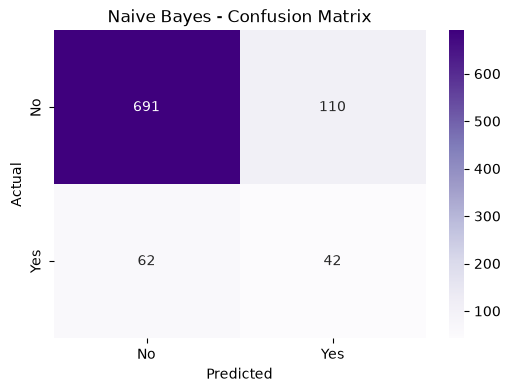

In [54]:
#Naive Bayes confusion matrix

cm_nb = confusion_matrix(y_test_encoded, y_pred_nb)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Support Vector Machine (SVM).
SVM attempts to find a decision boundary that separates two classes

In [55]:
#Import SVM
from sklearn.svm import SVC

In [56]:
#Create the SVM pipeline
svm_model = Pipeline(
    steps=[
        ("preprocessor", ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numerical_features),
                ("cat", OneHotEncoder(handle_unknown="ignore"),
                 categorical_features)
            ]
        )),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced",
            probability=True,
            random_state=42
        ))
    ]
)

print("SVM pipeline created successfully!")

SVM pipeline created successfully!


In [57]:
#Train SVM
svm_model.fit(X_train, y_train_encoded)

print("SVM training completed!")


e:\Mainpal_AI_Work\Python_Learning\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!


In [58]:
#Make predictions

y_pred_svm = svm_model.predict(X_test)

y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test_encoded[:10])

print("\nFirst 10 predicted values:")
print(y_pred_svm[:10])

First 10 actual values:
[1 0 0 0 0 0 0 1 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 1 0]


In [59]:
#Evaluate SVM
svm_accuracy = accuracy_score(y_test_encoded, y_pred_svm)

svm_precision = precision_score(
    y_test_encoded, y_pred_svm, zero_division=0
)

svm_recall = recall_score(
    y_test_encoded, y_pred_svm, zero_division=0
)

svm_f1 = f1_score(
    y_test_encoded, y_pred_svm, zero_division=0
)

svm_auc = roc_auc_score(y_test_encoded, y_prob_svm)

svm_mcc = matthews_corrcoef(y_test_encoded, y_pred_svm)

print("SVM RESULTS")
print("-----------")

print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))
print("AUC      :", round(svm_auc, 4))
print("MCC      :", round(svm_mcc, 4))

SVM RESULTS
-----------
Accuracy : 0.7901
Precision: 0.2913
Recall   : 0.5769
F1 Score : 0.3871
AUC      : 0.7502
MCC      : 0.3002


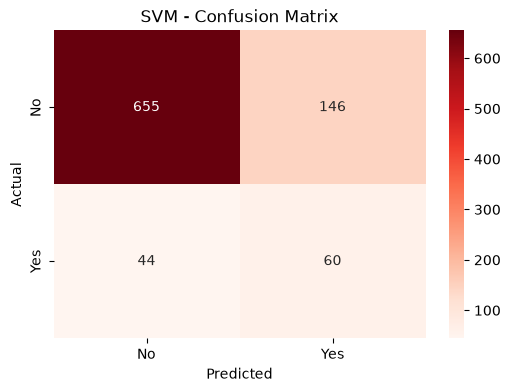

In [60]:
#SVM confusion matrix
cm_svm = confusion_matrix(y_test_encoded, y_pred_svm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Consolidated model comparison

In [63]:
results = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Naive Bayes",
        "SVM"
    ],

    "Accuracy": [
        lr_accuracy, dt_accuracy, knn_accuracy,
        nb_accuracy, svm_accuracy
    ],

    "Precision": [
        lr_precision, dt_precision, knn_precision,
        nb_precision, svm_precision
    ],

    "Recall": [
        lr_recall, dt_recall, knn_recall,
        nb_recall, svm_recall
    ],

    "F1 Score": [
        lr_f1, dt_f1, knn_f1,
        nb_f1, svm_f1
    ],

    "AUC": [
        lr_auc, dt_auc, knn_auc,
        nb_auc, svm_auc
    ],

    "MCC": [
        lr_mcc, dt_mcc, knn_mcc,
        nb_mcc, svm_mcc
    ]
}

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score    AUC    MCC
Logistic Regression    0.7050     0.2237  0.6346    0.3308 0.7350 0.2373
      Decision Tree    0.7724     0.2287  0.4135    0.2945 0.6788 0.1827
                KNN    0.8762     0.2778  0.0481    0.0820 0.6112 0.0727
        Naive Bayes    0.8099     0.2763  0.4038    0.3281 0.7166 0.2274
                SVM    0.7901     0.2913  0.5769    0.3871 0.7502 0.3002


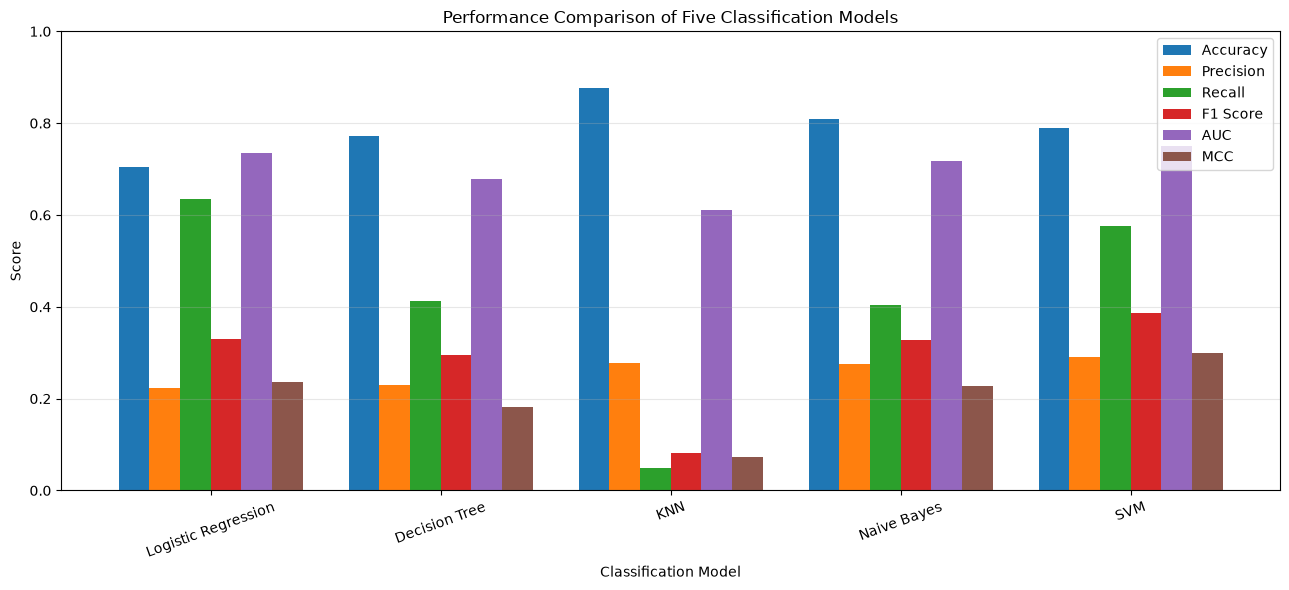

In [64]:
# Visualize model performance
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1 Score", "AUC", "MCC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Performance Comparison of Five Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Comparative Analysis of Classification Algorithms

Five classification algorithms were implemented and evaluated on the Bank Marketing dataset: Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes and Support Vector Machine.

The dataset contains 4,521 customer records and 16 original input features. The `duration` feature was excluded because it becomes available only after customer contact. The remaining 15 features were used for model development.

The target variable was imbalanced, with approximately 88.48% non-subscribers and 11.52% subscribers. Therefore, accuracy alone was not considered sufficient for evaluating the classifiers.

The experimental results showed that KNN achieved the highest accuracy of 87.62%. However, its recall was only 4.81%, indicating that it identified very few actual subscribers.

Logistic Regression achieved the highest recall of 63.46%, making it effective at identifying actual subscribers among the tested baseline models.

SVM achieved the highest F1-score (0.3871), ROC-AUC (0.7502) and Matthews Correlation Coefficient (0.3002). These results indicate a better overall balance between identifying subscribers and limiting incorrect positive predictions.

Based on these baseline experiments, SVM was selected as the leading candidate for further evaluation. The results also demonstrate the importance of considering multiple evaluation metrics when working with imbalanced classification datasets.

In [65]:
#Import required libraries
import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

print("Models directory created successfully!")

Models directory created successfully!


In [66]:
#Save all five models

# Dictionary containing all trained models
models = {
    "logistic_regression": logistic_model,
    "decision_tree": decision_tree_model,
    "knn": knn_model,
    "naive_bayes": naive_bayes_model,
    "svm": svm_model
}

# Save each model
for model_name, model in models.items():

    file_path = f"models/{model_name}.pkl"

    joblib.dump(model, file_path)

    print(f"{model_name} saved successfully!")

logistic_regression saved successfully!
decision_tree saved successfully!
knn saved successfully!
naive_bayes saved successfully!
svm saved successfully!


In [67]:
#Save the model comparison results
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [68]:
#Prepare test data for the Streamlit application

# Copy test features
test_data = X_test.copy()

# Add actual target values
test_data["y"] = y_test.values

# Save test data
test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

test_data.head()

Test dataset saved successfully!
Test dataset shape: (905, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
2032,59,management,married,primary,no,1727,no,no,telephone,25,may,4,358,2,failure,yes
943,40,technician,married,secondary,no,109,no,no,unknown,20,jun,22,-1,0,unknown,no
408,44,management,married,secondary,no,438,yes,no,telephone,8,may,3,303,1,failure,no
3034,29,services,married,primary,no,-102,no,no,unknown,4,jul,1,-1,0,unknown,no
3447,53,management,married,tertiary,no,146,no,no,unknown,30,may,1,-1,0,unknown,no


In [69]:
#Verify the saved files
print("Files available in project directory:")

for root, dirs, files in os.walk("."):

    # Ignore unnecessary system directories
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    for file in files:
        print(os.path.join(root, file))

Files available in project directory:
.\aa.txt
.\app.py
.\Assignment_1.ipynb
.\Assignment_2.ipynb
.\bank.csv
.\bike_test.csv
.\bike_train.csv
.\class_object.ipynb
.\decorators.ipynb
.\dictionary.ipynb
.\DNN_Assignment_1.ipynb
.\encapsulation.ipynb
.\example.txt
.\exceptional_handling.ipynb
.\file_handling.ipynb
.\file_name.txt
.\filter_function.ipynb
.\function.ipynb
.\generator.ipynb
.\import.ipynb
.\Indian_Liver_Patient_Dataset(ILPD).csv
.\inheritance.ipynb
.\iterator.ipynb
.\lambda.ipynb
.\List.ipynb
.\Machine_Learning_Assignment_1.ipynb
.\magic_functions.ipynb
.\map.ipynb
.\MFML_Assignment_1.ipynb
.\MFML_Assignment_2.ipynb
.\ML_Assignment_1.ipynb
.\ML_Assignment_2_2026AJ05122.ipynb
.\model_comparison.csv
.\new.ipynb
.\new_file.txt
.\numpy.ipynb
.\opertor_overloading.ipynb
.\pandas.ipynb
.\polymorphism.ipynb
.\requirement.txt
.\SampleSubmission.csv
.\sets.ipynb
.\student_performance_data.csv
.\test.ipynb
.\test_data.csv
.\tmp.txt
.\tupes.ipynb
.\LIBS\std_libs.ipynb
.\models\decision

In [70]:
#Test loading the SVM model

# Load saved SVM
loaded_svm = joblib.load(
    "models/svm.pkl"
)

# Predict using loaded model
test_predictions = loaded_svm.predict(X_test)

print("First 10 predictions from saved SVM:")
print(test_predictions[:10])

print("\nSaved model loaded and predictions generated successfully!")

First 10 predictions from saved SVM:
[0 0 0 0 0 0 0 0 1 0]

Saved model loaded and predictions generated successfully!
